# CNW-Grass gas exchange, 3: combine parameters

**What you will learn:** run the model on a grid of values of two parameters, gather the results in one table, and
see what limits photosynthesis.

**You need:** tutorial 2. **Run time:** about 30 seconds.

## 1. A grid: the two capacities

In Farquhar's model a leaf fixes CO₂ at the **lower** of two rates:

- the rate its enzyme **RuBisCO** allows (`Vc_max25_nitrogen_slope`: the RuBisCO per g of nitrogen);
- the rate its **electron transport** allows, driven by the light (`Jmax25_nitrogen_slope`).

Each combination of 4 values of each, from half to 1.5 times the default, is computed at noon: 16 simulations.
`variants` (from metafspm) writes the 16 combinations, each a set of parameters named after its values.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.cnwgrass.metafspm.simulation import parameters, simulate
from openalea.metafspm.scene.scenarios import variants

defaults = parameters().set_index("name")["value"]
factors = [0.5, 0.833, 1.167, 1.5]
grid = variants({}, {"Vc_max25_nitrogen_slope": [f * defaults["Vc_max25_nitrogen_slope"] for f in factors],
                     "Jmax25_nitrogen_slope": [f * defaults["Jmax25_nitrogen_slope"] for f in factors]},
                design="grid")
rows = []
for name, values in grid.items():
    row = simulate(values, hours=1, start_hour=12).summary.iloc[0]
    rows.append({"RuBisCO": round(values["Vc_max25_nitrogen_slope"] / defaults["Vc_max25_nitrogen_slope"], 2),
                 "electron transport": round(values["Jmax25_nitrogen_slope"]
                                             / defaults["Jmax25_nitrogen_slope"], 2),
                 "net_assimilation": row["net_assimilation"]})
table = pd.DataFrame(rows).pivot(index="RuBisCO", columns="electron transport", values="net_assimilation")
table.round(2)

electron transport,0.50,0.83,1.17,1.50
RuBisCO,,,,
0.50,7.04,9.76,10.83,11.19
0.83,7.04,9.77,11.55,12.74
1.17,7.04,9.77,11.55,12.74
1.50,7.04,9.77,11.55,12.74


The table gives the stand's net assimilation at noon (µmol m⁻² s⁻¹), its rows the RuBisCO (relative to the
default), its columns the electron transport. The same as curves:

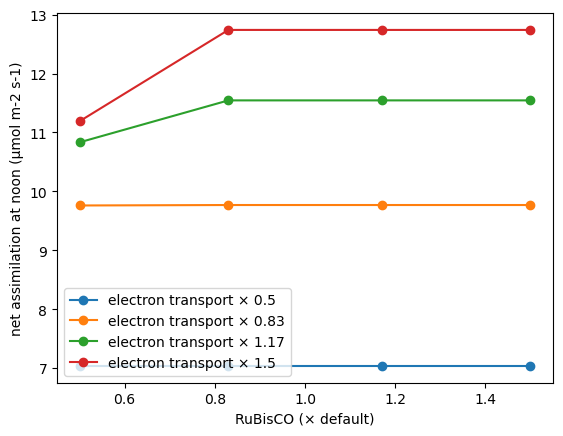

In [2]:
for column in table.columns:
    plt.plot(table.index, table[column], "o-", label=f"electron transport × {column}")
plt.xlabel("RuBisCO (× default)"); plt.ylabel("net assimilation at noon (µmol m-2 s-1)"); plt.legend();

**Reading the figure.** With little electron transport (the lowest curve), adding RuBisCO does nothing: the
electron transport, the light-driven part, limits every leaf. With more electron transport, the assimilation rises
with RuBisCO, up to a point where the electron transport limits again: the curves level off, each at its own height.
From the default (1 × each) up, RuBisCO has capacity to spare: only the electron transport matters. The two
parameters **combine**: the effect of one depends on the other.

## 2. Which one limits, leaf by leaf

In the corner of the grid where RuBisCO is scarce (× 0.5) and the electron transport abundant (× 1.5), which leaves
are limited by which rate? Raising each capacity a little in turn, element by element: the elements that gain more
from more RuBisCO are RuBisCO-limited, the others are limited by their electron transport.

In [3]:
corner = {"Vc_max25_nitrogen_slope": 0.5 * defaults["Vc_max25_nitrogen_slope"],
          "Jmax25_nitrogen_slope": 1.5 * defaults["Jmax25_nitrogen_slope"]}
base = simulate(corner, hours=1, start_hour=12).elements()
more_rubisco = simulate({**corner, "Vc_max25_nitrogen_slope": 0.6 * defaults["Vc_max25_nitrogen_slope"]}, hours=1,
                        start_hour=12).elements()
more_transport = simulate({**corner, "Jmax25_nitrogen_slope": 1.8 * defaults["Jmax25_nitrogen_slope"]}, hours=1,
                          start_hour=12).elements()
lit = base["An"] > 0
rubisco_limited = (more_rubisco["An"] - base["An"]) > (more_transport["An"] - base["An"])
light = pd.cut(base["PARa"][lit], [0, 200, 500, 1000, 2000])
rubisco_limited[lit].groupby(light, observed=True).mean().rename("share RuBisCO-limited").rename_axis(
    "PAR absorbed (µmol m-2 s-1)").round(2)

PAR absorbed (µmol m-2 s-1)
(0, 200]        0.00
(200, 500]      0.00
(500, 1000]     0.42
(1000, 2000]    1.00
Name: share RuBisCO-limited, dtype: float64

The elements in bright light are RuBisCO-limited, those in the shade are limited by their electron transport, the
light-driven part: the canopy's response to a capacity depends on how much of it is in the sun.

## Try it yourself

1. Repeat the grid at 8 h (`start_hour=8`), with less light. Which capacity limits more?
2. Repeat it with 800 ppm of CO₂ (`ambient_CO2=800.`). RuBisCO fixes CO₂ faster with more of it: does the
   limitation change?
3. Replace the electron transport by `surfacic_nitrogen` (1 to 3 g m⁻², a `simulate` argument): which of nitrogen
   and RuBisCO per nitrogen matters more?

**Next:** `04_sensitivity_analysis.ipynb`.